[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Joz84/cours_ml_ia/blob/main/tp/classer_photos/TP_classer_photos_CORRIGE.ipynb)

**CORRIGÉ**

# TP · Classer des photos


UE 5.7 « Data Science et IA » · Licence STES · Université de la Polynésie française

Corail sain, pâle ou blanchi ; type de déchet ; miconia ou autre végétation : trois problèmes du cours, et un seul principe. **Une photo entre, une classe sort.** Dans ce TP, vous entraînez un tel modèle en **réutilisant un réseau déjà entraîné** (le **transfert d'apprentissage**). Vous l'évaluez ensuite avec les outils de la séance 6, vous l'utilisez sur des photos nouvelles, et vous vérifiez **où il regarde**.

- **Durée :** environ 1 h 30, dont quelques minutes d'entraînement avec un GPU.
- **En binôme**, dans **Google Colab**. Vous n'avez rien à installer.
- **Chaque cellule tient en une ou deux lignes.** Elle appelle une fonction de la boîte à outils `outils_photos.py`, qui affiche en français ce qu'il faut voir.
- **Vous ne modifiez que la cellule RÉGLAGES**, et les deux cellules **DÉCISION** (les photos à écarter, les limites du modèle).
- **Si une cellule plante**, copiez-la avec le message d'erreur dans ChatGPT ou Claude, et demandez : « Explique-moi cette erreur simplement. »

> Ce TP existe aussi en **version exhaustive**, qui montre tout le code cellule par cellule, avec plus de questions et de bonus : [Annexe · Classer des photos – exhaustif](../classification_images/README.md).

## Pour vos propres photos

**Le carnet marche tel quel pour 2, 3, 4 ou 5 classes.** Le nombre de classes et leurs noms ne sont écrits nulle part : le carnet les lit dans les noms des sous-dossiers. **Un dossier par classe, c'est l'étiquette.**

```text
coraux/              ← le dossier que vous indiquez dans RÉGLAGES
├── sain/            ← un sous-dossier par classe : son nom EST l'étiquette
├── pale/            ← environ 300 photos par classe, sans accent ni espace dans les noms
└── blanchi/
```

1. Rangez vos photos dans votre Google Drive comme ci-dessus. Utilisez des photos en JPEG ou PNG : les photos HEIC d'iPhone ne sont pas lues, exportez-les d'abord en JPEG.
2. Dans RÉGLAGES, mettez le chemin de votre dossier, par exemple `PHOTOS = "/content/drive/MyDrive/coraux"`, et celui d'un dossier de photos jamais montrées au modèle dans `PHOTOS_NOUVELLES`.
3. Relisez `AUGMENTATIONS` : mettez `False` devant ce qui changerait la classe de vos photos.
4. Exécutez le carnet dans l'ordre. Aucune autre cellule ne change.

> **Ce que ce carnet ne fait pas** : trouver et compter les objets dans une photo (la *détection*) ; délimiter une zone pixel par pixel (la *segmentation*) ; plus d'une dizaine de classes ; les images médicales. Parlez-en avec l'enseignant.

## Le rituel

> **Je prédis** : avant une cellule qui donne un chiffre, j'écris mon pari à la ligne « Je prédis ».
> **J'exécute** : je lance la cellule.
> **Je constate** : j'écris deux phrases sur ce que j'observe.

## Les photos d'exemple

Pour que le carnet tourne avant que vous ayez vos photos, il est livré avec **900 photos de fleurs** en 3 classes : `marguerite`, `tournesol` et `tulipe`, 300 photos chacune. S'y ajoutent **32 photos nouvelles**, jamais montrées au modèle, dont 8 roses et pissenlits, **deux fleurs que le modèle ne connaît pas**. Ce sont de vraies photos, de qualité inégale, comme les vôtres.

Elles viennent du jeu « flower_photos » de TensorFlow, publié sous licence [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/). Les auteurs sont listés dans chaque zip. Le détail est dans [la version exhaustive](../classification_images/README.md#les-données-d'exemple).

## Le carnet

### Réglages · La seule cellule à modifier

Pour l'exemple, ne changez rien. Pour vos photos, c'est ici, et seulement ici.

In [1]:
# ===================== RÉGLAGES : la seule cellule à modifier =====================
PHOTOS = "https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/data/images_exemple.zip"  # vos photos : un zip, ou un dossier du Drive, par ex. "/content/drive/MyDrive/coraux"
PHOTOS_NOUVELLES = "https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/data/photos_nouvelles.zip"  # des photos jamais montrées au modèle
TAILLE = 256              # les photos sont mises en carré, TAILLE x TAILLE pixels
PART_VALIDATION = 0.2     # la part des photos gardée pour l'examen (0.2 = 20 %)
EPOQUES = 10              # le nombre maximum de passages sur les photos d'entraînement
SEUIL = 0.6               # en dessous de cette confiance, la photo part « à vérifier par un humain »
AUGMENTATIONS = {         # les transformations permises (True) ou interdites (False)
    "miroir": True,       # retourner la photo de gauche à droite (False si le sens compte : texte, flèche)
    "rotation": True,     # tourner un peu, de 10 degrés au plus
    "zoom": True,         # zoomer ou dézoomer un peu, de 10 % au plus
    "luminosite": True,   # éclaircir ou assombrir un peu
    "couleur": False,     # changer les teintes : mettre False pour le corail, la couleur EST la classe
}
DOSSIER_SORTIE = "/content/drive/MyDrive/TP_photos"   # le dossier du Drive où enregistrer le modèle et sa fiche
# ===================================================================================

### Outils · Le GPU et la boîte à outils

Avant tout, **activez le GPU**, une carte de calcul qui accélère beaucoup l'entraînement : menu **Exécution → Modifier le type d'exécution → GPU** (par exemple « T4 GPU ») → **Enregistrer**. Faites-le au tout début, car cela redémarre Colab.

La cellule télécharge la boîte à outils, si elle n'est pas déjà là, et vérifie le GPU.

In [2]:
import os, urllib.request
if not os.path.exists("outils_photos.py"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/tp/classer_photos/outils_photos.py", "outils_photos.py")
from outils_photos import *
verifier_gpu()

ATTENTION : pas de GPU. L'entraînement marchera, mais prendra une heure au lieu de quelques minutes sur un gros dossier de photos.
Menu Exécution → Modifier le type d'exécution → GPU, puis relancez le carnet depuis le début.


**Résultat attendu**

```text
GPU trouvé : l'entraînement prendra quelques minutes.
```

Sans GPU, un message « ATTENTION : pas de GPU » vous dit quoi faire. Le carnet marche quand même, plus lentement.

### Étape 0 · Collecter et étiqueter

*Le cours : ≈ 300 photos par classe, équilibré, varié, bien étiqueté, représentatif du terrain.* **Les features sont des pixels ; la cible est le nom du dossier.** La cellule lit les sous-dossiers, compte les photos de chacun et montre 9 photos au hasard avec leur étiquette.

**Je prédis :** combien de classes, combien de photos en tout ? …

3 classes, lues dans les noms des sous-dossiers : ['marguerite', 'tournesol', 'tulipe']
Photos en tout : 900
    classe  photos  fichiers non lus
marguerite     300                 0
 tournesol     300                 0
    tulipe     300                 0


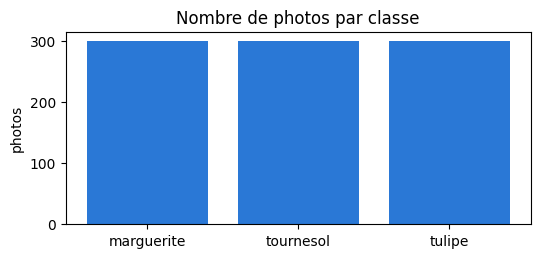

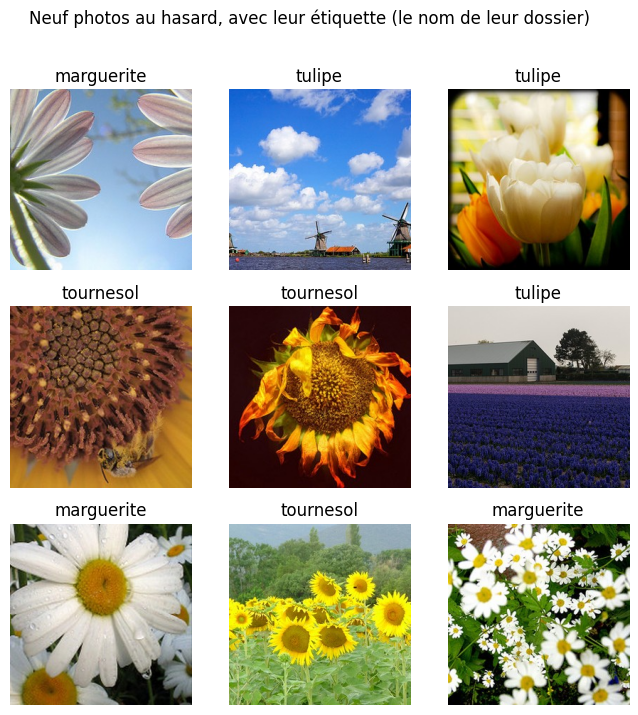

In [3]:
projet = lire_photos(PHOTOS, TAILLE)

**Résultat attendu**

```text
3 classes, lues dans les noms des sous-dossiers : ['marguerite', 'tournesol', 'tulipe']
Photos en tout : 900
    classe  photos  fichiers non lus
marguerite     300                 0
 tournesol     300                 0
    tulipe     300                 0
```

Puis un graphique en barres (une barre par classe) et une grille de 9 photos.

**Questions**
- **Q1.** Le jeu est-il équilibré ? Si une classe avait moins de la moitié des photos des autres, que feriez-vous ? (Cours : sous-échantillonner les autres, ou aller chercher des photos.)

**Réponse.** **Q1.** Oui : **3 classes de 300 photos**, parfaitement équilibrées. Si une classe avait moins de la moitié des photos des autres, le modèle aurait intérêt à répondre plus souvent les grosses classes, et l'exactitude cacherait son échec sur la petite. On peut **sous-échantillonner** les autres classes, mais le mieux est d'**aller chercher** des photos de la classe qui manque.

### Étape 2 · Nettoyer : regarder

*Le cours : écarter les doublons, les photos floues, mal rangées, hors sujet.* La cellule affiche **20 photos au hasard de chaque classe**, chacune avec son **numéro**. Regardez-les vraiment, une par une, et notez les numéros des photos à écarter. Pour voir 20 autres photos, écrivez `montrer_planches(projet, tirage=2)`.

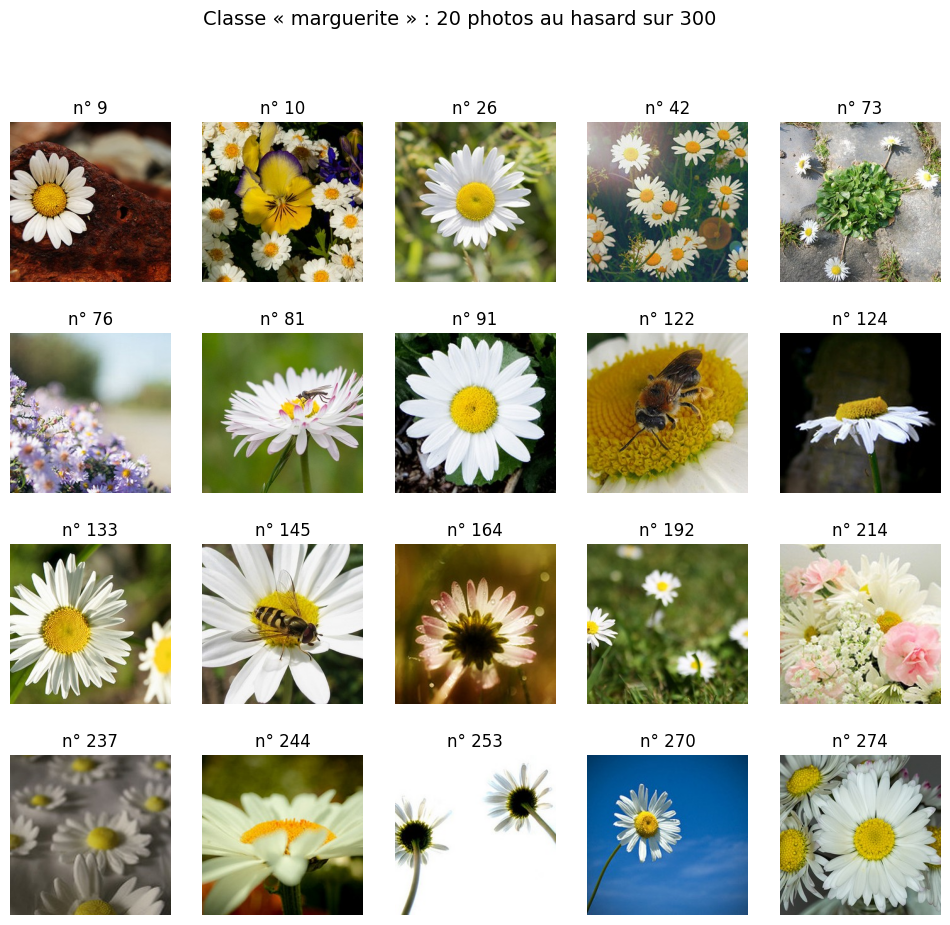

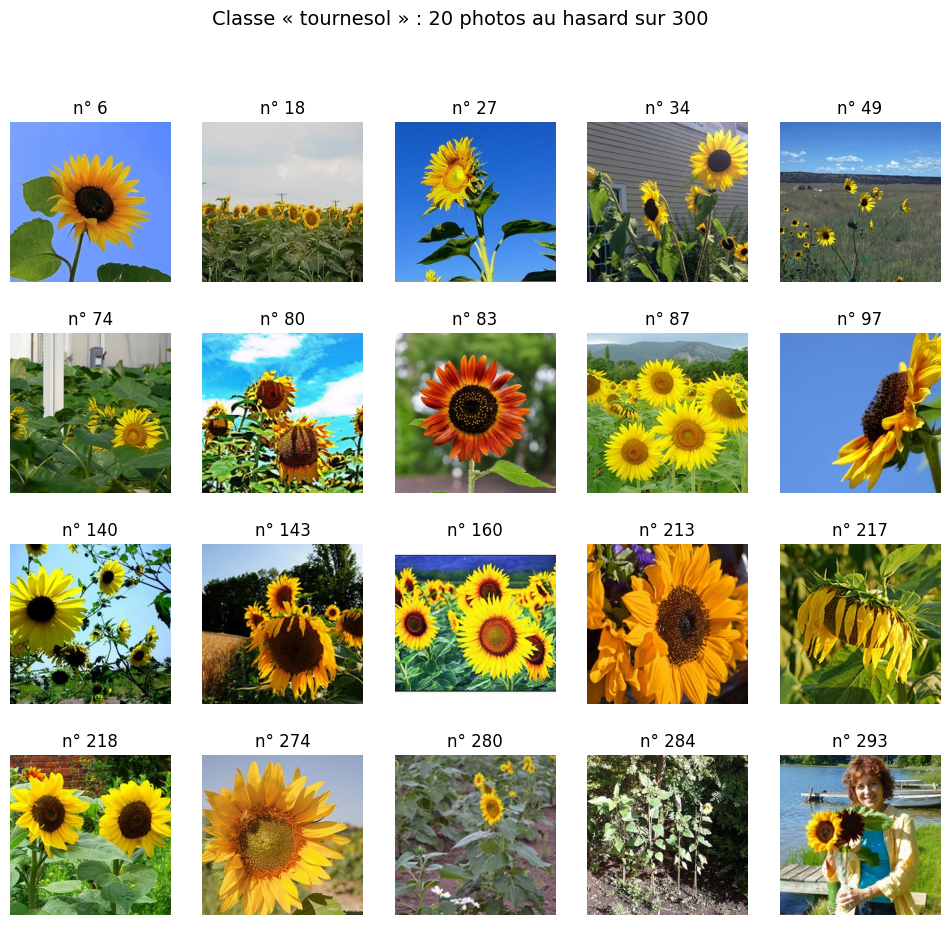

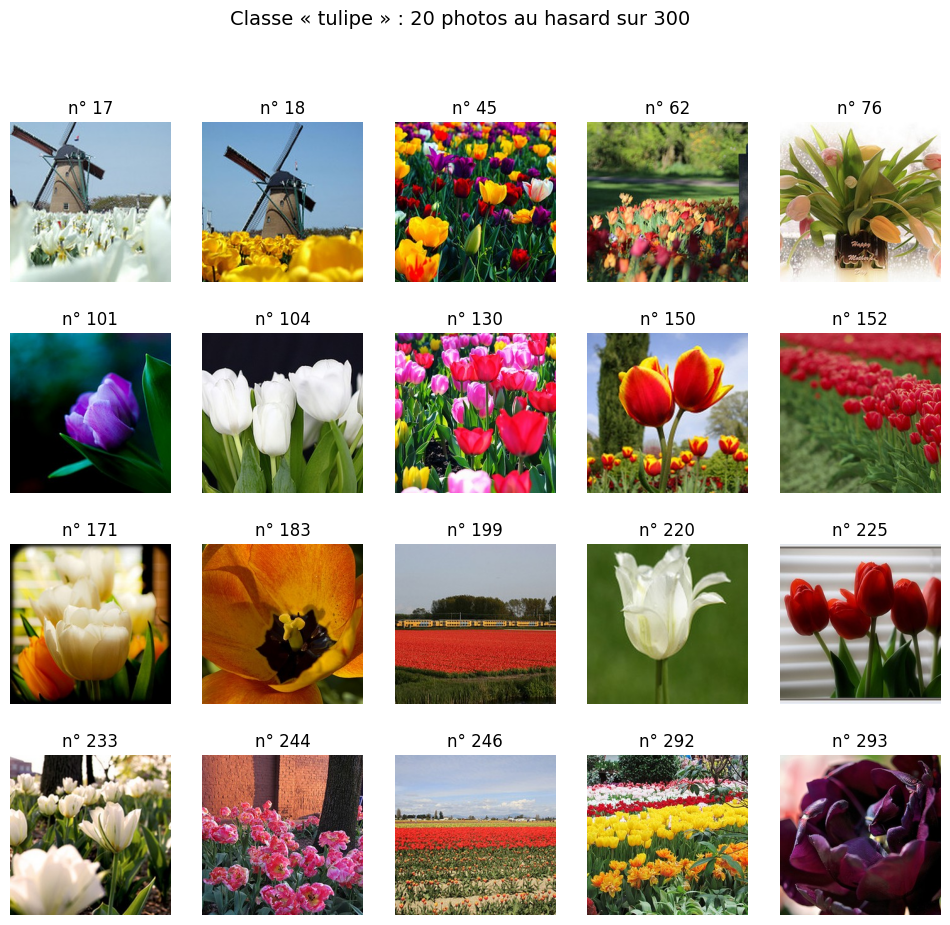

In [4]:
montrer_planches(projet)

**Résultat attendu :** une planche de 20 photos numérotées par classe.

### Étape 2 · Nettoyer : DÉCISION, écarter des photos

Écrivez les numéros notés, classe par classe, comme dans l'exemple en commentaire. La cellule copie les photos dans un **dossier de travail, sans celles-là**, et sans les fichiers abîmés. **Votre Drive n'est pas modifié** : on ne travaille jamais sur l'original. Laisser `{}` est aussi une décision.

In [5]:
A_ECARTER = {                   # DÉCISION
    "marguerite": [76, 214],     # 76 : des asters violets, mal rangés ; 214 : un bouquet d'œillets roses, hors sujet
    "tournesol": [293],          # une personne au premier plan, qui cache presque la fleur
    "tulipe": [17],              # quasi-doublon de la n° 18 : le même moulin, la même prise de vue
}
ecarter(projet, A_ECARTER)

Écartées par vous : 4
  - marguerite n° 76 (17357636476_1953c07aa4_n.jpg)
  - marguerite n° 214 (517054463_036db655a1_m.jpg)
  - tournesol n° 293 (9497774249_7f5ae70927_m.jpg)
  - tulipe n° 17 (130684927_a05164ba13_m.jpg)
Abîmées, illisibles : 0 []
Photos gardées par classe : {'marguerite': 298, 'tournesol': 299, 'tulipe': 299}
L'original n'a pas été modifié : le carnet travaille sur une copie.


**Résultat attendu**, si vous n'écartez rien

```text
Écartées par vous : 0
Abîmées, illisibles : 0 []
Photos gardées par classe : {'marguerite': 300, 'tournesol': 300, 'tulipe': 300}
L'original n'a pas été modifié : le carnet travaille sur une copie.
```

Les résultats attendus des cellules suivantes sont ceux du corrigé, qui écarte 4 photos (896 photos gardées). Si vous en écartez d'autres, vos chiffres seront un peu différents.

**Questions**
- **Q2.** Quelles photos avez-vous écartées, et pourquoi (floue, hors sujet, mal rangée, doublon) ? Y en a-t-il que vous avez hésité à écarter ?

**Réponse.** **Q2.** Sur les 60 photos regardées, le corrigé en écarte 4 : `marguerite` n° 76 montre des **asters violets**, une autre fleur (**mal rangée**) ; `marguerite` n° 214 est un bouquet d'œillets roses où la marguerite se voit à peine (**hors sujet**) ; `tournesol` n° 293 montre surtout une **personne**, qui cache presque la fleur (et une photo de personne pose une question de vie privée) ; `tulipe` n° 17 est un **quasi-doublon** de la n° 18 : le même moulin, la même prise de vue. Hésitations, photos gardées : `marguerite` n° 10 (une pensée jaune au milieu de vraies marguerites), `tournesol` n° 284 (de jeunes plants sans fleur). Une fois les cellules suivantes exécutées, on découvre d'autres intrus, par exemple une peintre devant son chevalet rangée dans `tulipe` (étape 6) : on ne voit pas tout en regardant 20 photos sur 300.

### Étape 1 · Séparer 80 / 20, avant tout le reste

On met de côté **20 % des photos pour l'examen** (la **validation**). Le modèle ne les verra jamais pendant l'entraînement : c'est sur elles qu'on le jugera. Dans le cours, cette séparation est l'étape 1 ; dans le carnet, elle vient juste après le nettoyage, et toujours **avant** l'entraînement. Chaque photo reçoit l'étiquette de son dossier : **il n'y a rien à encoder.**

**Je prédis :** combien de photos pour l'entraînement ? …

In [6]:
separer(projet, PART_VALIDATION)

896 photos : 717 pour l'entraînement, 179 pour l'examen (la validation).
Le modèle les regardera par lots de 32 : 23 lots d'entraînement, 6 lots de validation.
L'étiquette de chaque photo est le nom de son dossier : il n'y a rien à encoder.
            entraînement  validation
marguerite           237          61
tournesol            237          62
tulipe               243          56


**Résultat attendu**

```text
896 photos : 717 pour l'entraînement, 179 pour l'examen (la validation).
Le modèle les regardera par lots de 32 : 23 lots d'entraînement, 6 lots de validation.
L'étiquette de chaque photo est le nom de son dossier : il n'y a rien à encoder.
            entraînement  validation
marguerite           237          61
tournesol            237          62
tulipe               243          56
```

**Questions**
- **Q3.** Le piège des rafales : si 20 photos du même massif de corail sont prises dans la même plongée, que se passe-t-il quand on les répartit au hasard entre entraînement et examen ? Pourquoi vaut-il mieux garder des sites entiers pour l'examen ?

**Réponse.** **Q3.** Deux photos presque identiques peuvent tomber l'une dans l'entraînement, l'autre dans l'examen : le modèle reconnaît la jumelle qu'il a déjà vue au lieu de classer une photo nouvelle. L'exactitude mesurée est alors trop belle, et elle s'effondre sur un nouveau site. En gardant des **sites entiers** pour l'examen, on mesure ce qui compte : le modèle marche-t-il sur un site qu'il n'a jamais vu ? Dans l'exemple, les tulipes n° 17 et n° 18 (le même moulin) sont ce genre de jumelles.

### Étape 3 · Redimensionner, normaliser, augmenter

Un réseau veut des photos **de la même taille**, avec des pixels **dans une petite plage de valeurs**. Une photo, pour la machine, c'est **256 × 256 × 3 = 196 608 nombres** entre 0 et 255. MobileNetV2, le réseau qu'on réutilise, les veut entre −1 et 1 : le modèle s'en charge lui-même.

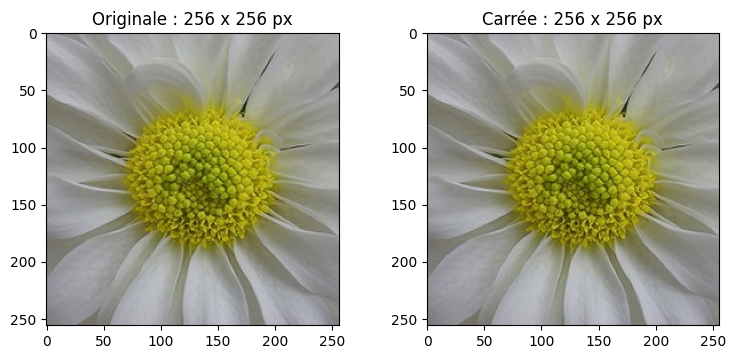

Une photo, pour la machine : 196 608 nombres = 256 x 256 x 3
Pixels avant : de 0 à 235 · le pixel en haut à gauche (rouge, vert, bleu) : [153 153 161]
Pixels après : de -1.0 à 0.84 · le même pixel : [0.2  0.2  0.26]


In [7]:
avant_apres(projet)

**Résultat attendu**

```text
Une photo, pour la machine : 196 608 nombres = 256 x 256 x 3
Pixels avant : de 0 à 235 · le pixel en haut à gauche (rouge, vert, bleu) : [153 153 161]
Pixels après : de -1.0 à 0.84 · le même pixel : [0.2  0.2  0.26]
```

**Augmenter**, c'est montrer au modèle, à chaque époque, une version un peu transformée de chaque photo d'entraînement. Il apprend ainsi que ces changements ne comptent pas. L'augmentation se fait **à la volée, sur l'entraînement seulement** : le dossier ne grossit pas, et **les photos d'examen restent brutes**. La cellule construit l'augmentation à partir de la liste `AUGMENTATIONS` de RÉGLAGES, puis le vérifie.

Augmentations actives : ['miroir', 'rotation', 'zoom', 'luminosite']
Interdites : ['couleur']


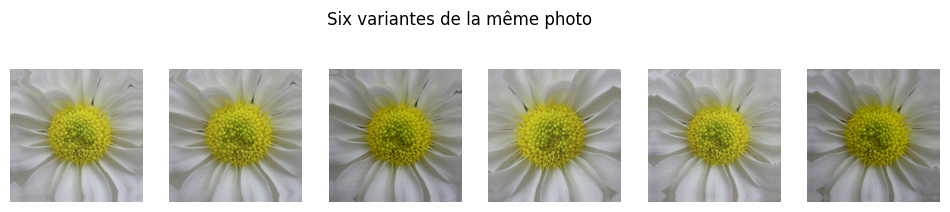

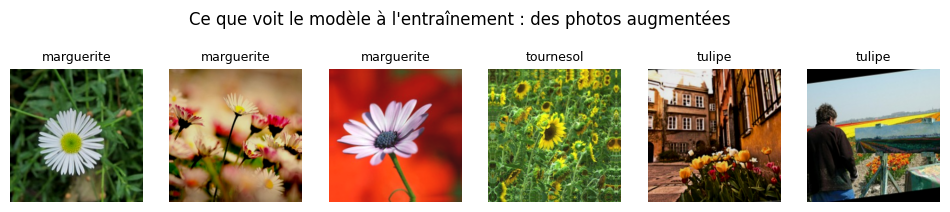

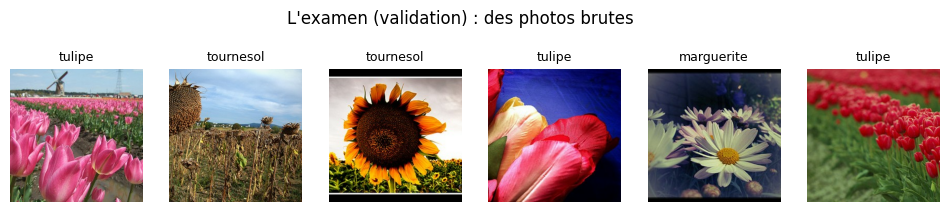

In [8]:
augmenter(projet, AUGMENTATIONS)

**Résultat attendu**

```text
Augmentations actives : ['miroir', 'rotation', 'zoom', 'luminosite']
Interdites : ['couleur']
```

Puis trois rangées de photos : six variantes d'une même photo ; un lot d'entraînement, parfois incliné ou zoomé ; un lot de validation, net et droit.

**Questions**
- **Q4.** Jamais une transformation qui change la classe : pour le corail, la couleur est interdite. Pour les fleurs de l'exemple, faut-il interdire la couleur ? Et pour vos classes ?

**Réponse.** **Q4.** Oui, pour les fleurs aussi, la couleur doit rester interdite : une marguerite est blanche, un tournesol jaune, une tulipe souvent rouge ou rose. Changer les teintes fabriquerait des tournesols rouges ou des marguerites violettes, et brouillerait l'indice le plus utile. Le miroir, une rotation légère, un zoom léger et la luminosité ne changent pas l'espèce : ils sont permis. Pour le corail, c'est encore plus net : la couleur *est* la classe (sain, pâle, blanchi).

### Étape 4 · Importer et créer le modèle

**Un neurone, c'est la régression logistique de la séance 6.** Un réseau, ce sont des neurones en couches. Pour les images, des **filtres qui glissent** sur la photo trouvent des traits, puis des textures, puis des objets. **On ne part jamais de zéro** : on réutilise **MobileNetV2**, déjà entraîné sur 1,4 million de photos (ImageNet). On **gèle ses poids**, et on remplace sa **dernière couche** par une neuve, **une sortie par classe**. C'est le **transfert d'apprentissage**.

**Je prédis :** quelle part des poids va vraiment apprendre ? Plus de la moitié, 10 %, moins de 1 % ? …

In [9]:
creer_modele(projet)

Le modèle, de l'entrée à la sortie :
  1. redimensionner et normaliser : la photo passe en 224 x 224, ses pixels entre -1 et 1
  2. MobileNetV2, pré-entraîné sur ImageNet, GELÉ : il décrit la photo par 1 280 nombres
  3. moyenne puis oubli (Dropout) : résumer, et éteindre au hasard 20 % des nombres pendant l'entraînement
  4. decision : la dernière couche, NEUVE, 3 sorties = une probabilité par classe ['marguerite', 'tournesol', 'tulipe']

Poids gelés (appris sur ImageNet, on n'y touche pas) : 2 257 984
Poids entraînés (la dernière couche, neuve)           : 3 843
Part des poids qui apprennent : 0,17 %


**Résultat attendu**

```text
Le modèle, de l'entrée à la sortie :
  1. redimensionner et normaliser : la photo passe en 224 x 224, ses pixels entre -1 et 1
  2. MobileNetV2, pré-entraîné sur ImageNet, GELÉ : il décrit la photo par 1 280 nombres
  3. moyenne puis oubli (Dropout) : résumer, et éteindre au hasard 20 % des nombres pendant l'entraînement
  4. decision : la dernière couche, NEUVE, 3 sorties = une probabilité par classe ['marguerite', 'tournesol', 'tulipe']

Poids gelés (appris sur ImageNet, on n'y touche pas) : 2 257 984
Poids entraînés (la dernière couche, neuve)           : 3 843
Part des poids qui apprennent : 0,17 %
```

**Questions**
- **Q5.** Combien de poids sont gelés, combien sont entraînés ? Pourquoi 300 photos par classe suffisent-elles ?

**Réponse.** **Q5.** **2 257 984 poids gelés**, ceux de MobileNetV2, et **3 843 poids entraînés**, ceux de la dernière couche (1 280 nombres × 3 sorties, plus 3) : **0,17 %** des poids apprennent. Le réseau sait déjà voir des traits, des textures et des formes ; il ne reste qu'à apprendre comment combiner ses 1 280 nombres pour séparer 3 fleurs. Pour régler 3 843 poids, 300 photos par classe suffisent ; pour en régler 2,3 millions, il en faudrait des dizaines de milliers. C'est la diapo « on ne part jamais de zéro ».

### Étape 5 · Entraîner (`fit`)

Une **époque**, c'est un passage sur toutes les photos d'entraînement. Après chaque époque, la cellule affiche l'exactitude sur l'entraînement et sur la validation. **Arrêt automatique** : si la validation ne progresse plus pendant 3 époques, l'entraînement s'arrête, et le modèle reprend les poids de sa meilleure époque. Puis les **deux courbes**. Quand la validation cesse de monter alors que l'entraînement continue, le modèle apprend par cœur : c'est le **sur-apprentissage**.

**Je prédis :** quelle exactitude de validation à la fin ? …

Époque  1/10 · exactitude entraînement 68,6 % · validation 86,6 % · 14 s


Époque  2/10 · exactitude entraînement 86,8 % · validation 91,6 % · 13 s


Époque  3/10 · exactitude entraînement 90,2 % · validation 92,7 % · 11 s


Époque  4/10 · exactitude entraînement 92,1 % · validation 93,3 % · 8 s


Époque  5/10 · exactitude entraînement 91,9 % · validation 93,3 % · 7 s


Époque  6/10 · exactitude entraînement 93,9 % · validation 93,9 % · 8 s


Époque  7/10 · exactitude entraînement 96,1 % · validation 93,3 % · 7 s


Époque  8/10 · exactitude entraînement 95,4 % · validation 93,9 % · 8 s


Époque  9/10 · exactitude entraînement 96,2 % · validation 93,3 % · 7 s

Arrêt automatique : la validation ne progresse plus depuis 3 époques.
Le modèle reprend les poids de sa meilleure époque : l'époque 6, exactitude de validation 93,9 %.
9 époques en 1,4 minutes, soit 9 s par époque.


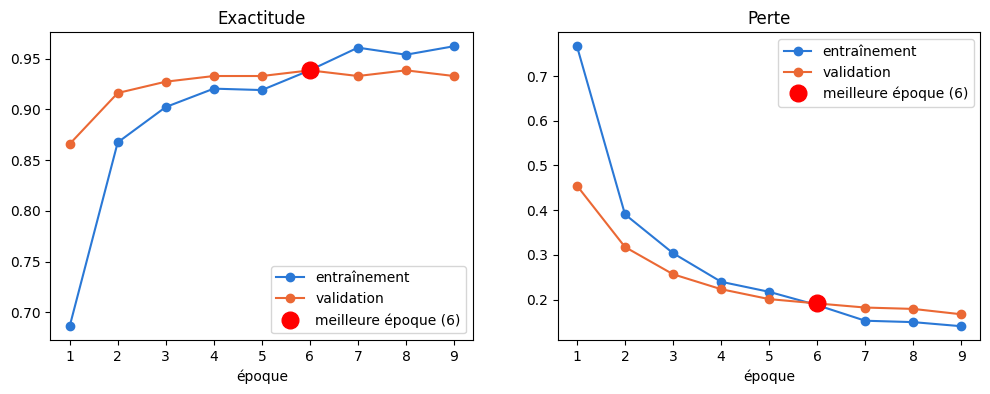

In [10]:
entrainer(projet, EPOQUES)

**Résultat attendu** (les chiffres changent un peu d'une machine à l'autre)

```text
Époque  1/10 · exactitude entraînement 68,6 % · validation 86,6 % · 14 s
Époque  2/10 · exactitude entraînement 86,8 % · validation 91,6 % · 13 s
Époque  3/10 · exactitude entraînement 90,2 % · validation 92,7 % · 11 s
Époque  4/10 · exactitude entraînement 92,1 % · validation 93,3 % · 8 s
Époque  5/10 · exactitude entraînement 91,9 % · validation 93,3 % · 7 s
Époque  6/10 · exactitude entraînement 93,9 % · validation 93,9 % · 8 s
Époque  7/10 · exactitude entraînement 96,1 % · validation 93,3 % · 7 s
Époque  8/10 · exactitude entraînement 95,4 % · validation 93,9 % · 8 s
Époque  9/10 · exactitude entraînement 96,2 % · validation 93,3 % · 7 s

Arrêt automatique : la validation ne progresse plus depuis 3 époques.
Le modèle reprend les poids de sa meilleure époque : l'époque 6, exactitude de validation 93,9 %.
9 époques en 1,4 minutes, soit 9 s par époque.
```

Puis deux graphiques : l'exactitude, qui monte vite puis plafonne, et la **perte**, un nombre qui mesure à quel point le modèle se trompe, et qui descend.

**Questions**
- **Q6.** À quelle époque fallait-il s'arrêter ? Y a-t-il sur-apprentissage ? Au début, pourquoi la validation est-elle *au-dessus* de l'entraînement ? (Indice : l'augmentation ne touche que l'entraînement.)

**Réponse.** **Q6.** La validation atteint son meilleur niveau, **93,9 %**, à l'**époque 6** : c'est là qu'il fallait s'arrêter, et c'est ce qu'a fait l'arrêt automatique (arrêt à l'époque 9, poids de l'époque 6). Ensuite, l'entraînement continue de monter (96 %) alors que la validation stagne autour de 93-94 % : c'est un **début de sur-apprentissage**, encore léger. Au début, la validation est au-dessus de l'entraînement (86,6 % contre 68,6 % à la 1ʳᵉ époque) : l'exactitude d'entraînement est mesurée sur des photos **augmentées**, avec l'oubli actif, et en moyenne pendant une époque où le modèle progresse encore ; la validation est mesurée sur des photos brutes, à la fin de l'époque.

### Étape 6 · Évaluer

Les outils de la séance 6, pas un de plus : l'**exactitude**, comparée au **modèle paresseux** (qui répond toujours la même classe) ; la **matrice de confusion** (en lignes, la classe **vraiment** ; en colonnes, la classe **prédite**) ; le **rappel** et la **précision** de chaque classe ; et les photos mal classées.

**Je prédis :** combien de photos mal classées ? …

Exactitude sur la validation : 93,9 % (168 photos justes sur 179)
Modèle paresseux (répond toujours « tulipe », la classe la plus fréquente) : 31,3 %


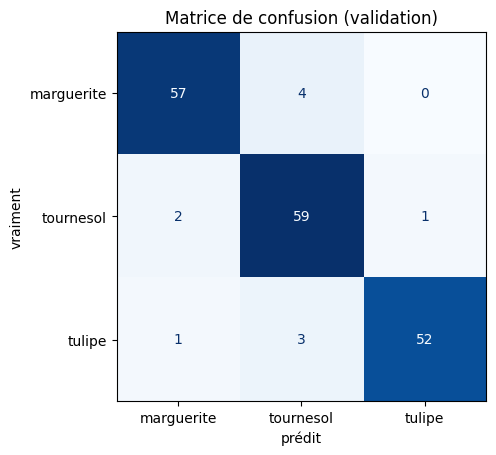

Rappel : parmi les photos VRAIMENT de la classe, la part trouvée.
Précision : parmi les photos PRÉDITES de la classe, la part juste.
            rappel  précision  photos
marguerite    0.93       0.95      61
tournesol     0.95       0.89      62
tulipe        0.93       0.98      56

11 photos mal classées sur 179 : vraie classe → classe prédite (confiance)


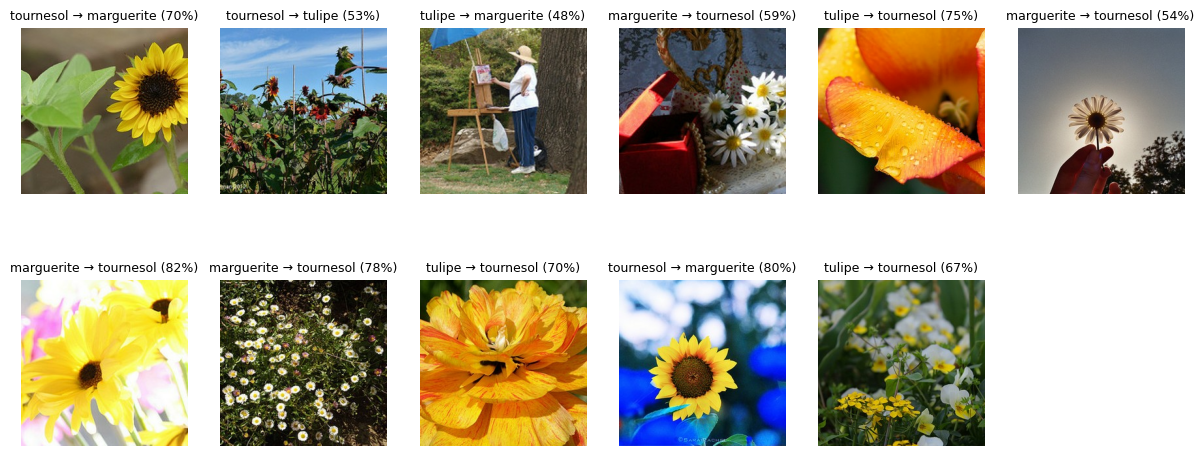

In [11]:
evaluer(projet)

**Résultat attendu**

```text
Exactitude sur la validation : 93,9 % (168 photos justes sur 179)
Modèle paresseux (répond toujours « tulipe », la classe la plus fréquente) : 31,3 %
Rappel : parmi les photos VRAIMENT de la classe, la part trouvée.
Précision : parmi les photos PRÉDITES de la classe, la part juste.
            rappel  précision  photos
marguerite    0.93       0.95      61
tournesol     0.95       0.89      62
tulipe        0.93       0.98      56

11 photos mal classées sur 179 : vraie classe → classe prédite (confiance)
```

Avec la matrice de confusion et la grille des photos mal classées, chacune avec « vraie classe → classe prédite (confiance) ».

**Questions**
- **Q7.** Le modèle bat-il nettement le modèle paresseux ? Quelle classe est la plus souvent confondue, et avec laquelle ? Est-ce une erreur qu'un humain ferait aussi ? Dans votre projet, quelle erreur coûterait le plus cher, et quel rappel surveilleriez-vous ?

**Réponse.** **Q7.** Oui, nettement : **93,9 %** contre **31,3 %** pour le modèle paresseux, soit 63 points de plus. La confusion la plus fréquente : des **marguerites prises pour des tournesols** (4 photos), puis des **tulipes prises pour des tournesols** (3). Beaucoup d'erreurs sont difficiles pour un humain aussi : des marguerites jaunes, un gros plan de pétales orange, un massif de petites fleurs blanches vu de loin, une fleur à contre-jour. Certaines ne sont pas des erreurs du modèle : une photo d'une **peintre devant son chevalet** est rangée dans `tulipe`, c'est l'étiquette qui est fausse. Pour le corail, l'erreur la plus coûteuse serait de dire « sain » à un corail blanchi : on surveillerait le **rappel de `blanchi`**. Pour le miconia, le **rappel de `miconia`**.

### Étape 7 · Prédire (`predict`)

Pour une photo nouvelle, le modèle donne **une probabilité par classe**. On retient la plus grande ; si elle est **sous le seuil de confiance**, la photo part **« à vérifier par un humain »**. Changez le numéro pour essayer d'autres photos, ou écrivez `"televerser"` pour envoyer une photo de votre téléphone.

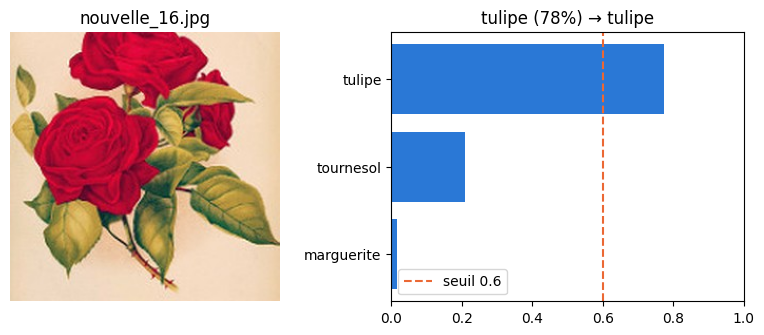

Probabilités : {'marguerite': 0.016, 'tournesol': 0.209, 'tulipe': 0.775}
Décision : tulipe


In [12]:
predire_une_photo(projet, PHOTOS_NOUVELLES, choix=16, seuil=SEUIL)   # À MODIFIER : le numéro de la photo, ou "televerser"

**Résultat attendu**

```text
Probabilités : {'marguerite': 0.016, 'tournesol': 0.209, 'tulipe': 0.775}
Décision : tulipe
```

La même chose sur **tout le dossier**. On obtient un tableau `fichier, classe, confiance, decision`, enregistré dans `predictions.csv`, puis compté par décision. **C'est la statistique du cas 2** : combien de photos de chaque type de déchet ? Ce tableau se nettoie, s'analyse et se trace comme ceux des séances 4 et 5.

**Je prédis :** combien de photos partiront « à vérifier » ? …

In [13]:
predire_dossier(projet, PHOTOS_NOUVELLES, seuil=SEUIL)

32 photos nouvelles. Les 10 premières lignes du tableau (enregistré dans predictions.csv) :
        fichier     classe  confiance   decision
nouvelle_01.jpg marguerite      0.965 marguerite
nouvelle_02.jpg  tournesol      0.950  tournesol
nouvelle_03.jpg marguerite      0.937 marguerite
nouvelle_04.jpg  tournesol      0.800  tournesol
nouvelle_05.jpg     tulipe      0.998     tulipe
nouvelle_06.jpg     tulipe      0.994     tulipe
nouvelle_07.jpg marguerite      0.940 marguerite
nouvelle_08.jpg  tournesol      0.929  tournesol
nouvelle_09.jpg     tulipe      0.990     tulipe
nouvelle_10.jpg     tulipe      0.947     tulipe

Combien de photos par décision, avec le seuil 0.6 :
decision
marguerite                  11
tulipe                      11
tournesol                    7
à vérifier par un humain     3

Et avec d'autres seuils :
  seuil 0.5 :   1 photos à vérifier sur 32
  seuil 0.6 :   3 photos à vérifier sur 32
  seuil 0.8 :   9 photos à vérifier sur 32


**Résultat attendu**

```text
32 photos nouvelles. Les 10 premières lignes du tableau (enregistré dans predictions.csv) :
        fichier     classe  confiance   decision
nouvelle_01.jpg marguerite      0.965 marguerite
nouvelle_02.jpg  tournesol      0.950  tournesol
nouvelle_03.jpg marguerite      0.937 marguerite
…

Combien de photos par décision, avec le seuil 0.6 :
decision
marguerite                  11
tulipe                      11
tournesol                    7
à vérifier par un humain     3

Et avec d'autres seuils :
  seuil 0.5 :   1 photos à vérifier sur 32
  seuil 0.6 :   3 photos à vérifier sur 32
  seuil 0.8 :   9 photos à vérifier sur 32
```

**Questions**
- **Q8.** Les photos 16, 19, 25 et 27 de l'exemple sont des roses, une fleur que le modèle n'a jamais vue. Que répond-il, et avec quelle confiance ? Pourquoi ne peut-il pas dire « je ne sais pas » ? Pour une association qui trie des milliers de photos avec deux bénévoles, quel seuil choisiriez-vous ?

**Réponse.** **Q8.** Les 4 roses sont toutes classées **tulipe**, avec des confiances de **66 % à 99,7 %** : aucune ne passe sous le seuil de 0,6. Les 4 pissenlits sont classés marguerite ou tournesol, à 75 % et plus. Le modèle ne peut pas dire « je ne sais pas » : sa dernière couche donne des probabilités **dont la somme fait 1**, il répartit donc toujours toute la confiance entre les classes qu'il connaît. Le seuil attrape les hésitations (ici, l'unique erreur sur les fleurs apprises, à 48 %), pas les fleurs inconnues. La parade : une classe `autre`, avec des photos de ce qu'on risque de rencontrer. Pour l'association : avec 0,6, 3 photos sur 32 partent à vérifier ; avec 0,8, 9 photos, soit plus d'un quart. Avec deux bénévoles et des milliers de photos, un seuil de **0,6 à 0,7** est raisonnable, à condition de vérifier de temps en temps un échantillon des photos acceptées.

### Étape 8 · Où regarde le modèle ?

Un bon score ne suffit pas. La **carte de chaleur** colore en rouge les zones de la photo qui ont le plus pesé dans la décision. **S'il regarde le fond, le site ou le matériel** (une règle, un cadre, la couleur du seau), c'est un **raccourci** : il a trouvé un indice qui marche sur vos photos, mais pas sur le terrain.

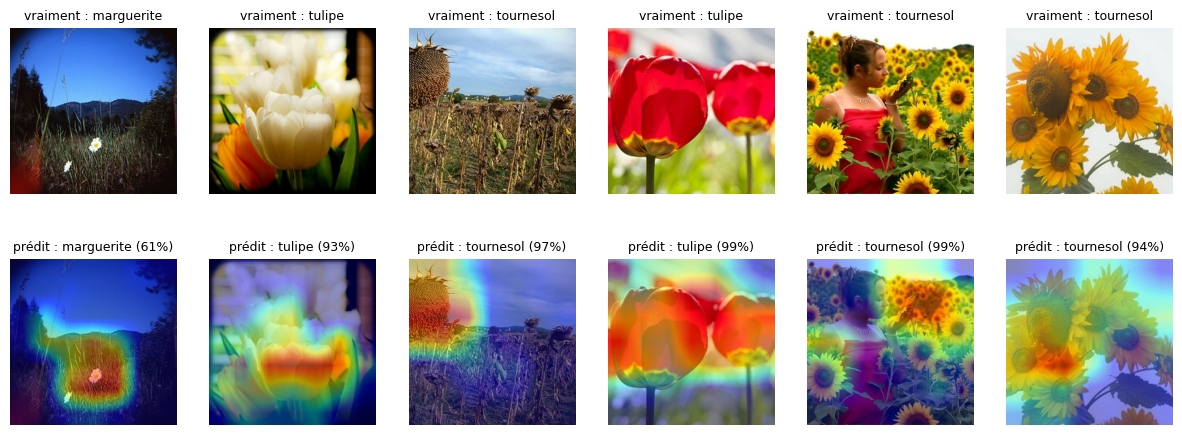

In [14]:
cartes_de_chaleur(projet)

**Résultat attendu :** six photos de validation, puis les mêmes avec leur carte de chaleur, du bleu (sans importance) au rouge (décisif).

> **Si le résultat déçoit**, dans cet ordre : vérifier les étiquettes (les photos mal classées sont-elles dans le bon dossier ?), ajouter de la variété (d'autres sites, heures, appareils), augmenter davantage, et seulement ensuite dégeler les dernières couches (bonus, en fin de carnet).
>
> **Si le résultat est trop beau** (99 % dès la 2ᵉ époque) : méfiance. Des photos en rafale de part et d'autre du partage (Q3), ou un raccourci (la carte de chaleur le montre).

**Questions**
- **Q9.** Les zones rouges sont-elles sur le sujet ou sur le fond ? Si c'est le fond, quelle étape faut-il reprendre ?

**Réponse.** **Q9.** Sur ces six photos, **les zones rouges sont sur les fleurs** : les tulipes, la tête de tournesol séchée à gauche, la petite marguerite dans l'herbe. Sur la photo d'une femme dans un champ de tournesols, la chaleur est sur les tournesols à droite, **pas sur la personne** : bon signe. Si les zones rouges tombaient sur le fond (le ciel, la pelouse, une personne), ce serait un **raccourci** : on reprendrait l'**étape 0**, en collectant des photos plus variées (des fleurs sur fond sombre et sur fond clair, avec et sans personne), puis l'**étape 2**, en écartant les photos où le sujet n'est pas la fleur.

### Étape 9 · Sauvegarder et documenter

Un modèle sans sa fiche, c'est un tableau propre sans son journal de nettoyage : personne ne peut savoir ce qu'il vaut. La cellule enregistre dans votre Drive le **modèle**, les **prédictions** et la **fiche du modèle** (`fiche_modele.md`). C'est **le journal de la séance 5, appliqué à un modèle**. Complétez d'abord les **limites connues** : les sites, les appareils et les conditions que le modèle a vus, et ceux qu'il n'a pas vus.

In [15]:
LIMITES = ("Photos de fleurs publiées sur Flickr, prises de jour, le plus souvent de près, par des appareils "
           "et des photographes très divers. Le modèle n'a vu ni les fleurs de Polynésie, ni des photos de nuit, "
           "ni d'autres fleurs que ces trois : une rose ou un pissenlit reçoivent quand même l'une des trois étiquettes.")   # DÉCISION
enregistrer(projet, DOSSIER_SORTIE, LIMITES)

Enregistrés dans sorties : ['fiche_modele.md', 'modele_photos.keras', 'predictions.csv']

# Fiche du modèle : marguerite, tournesol, tulipe

- **Date :** 23/11/2026
- **Photos :** `https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/data/images_exemple.zip`
- **Modèle :** MobileNetV2 pré-entraîné sur ImageNet, poids gelés ; dernière couche neuve à 3 sorties
- **Préparation :** photos recadrées en carré, 256 x 256 px ; 4 photo(s) écartée(s) à la main, 0 illisible(s)
- **Partage :** 717 photos pour l'entraînement, 179 pour la validation (photo par photo, graine 42)
- **Augmentations :** miroir, rotation, zoom, luminosite (interdites : couleur)
- **Entraînement :** 9 époques sur 10 au plus, meilleure époque 6, 1,4 minutes
- **Exactitude sur la validation :** 93,9 % (modèle paresseux : 31,3 %)
- **Seuil de confiance :** 0.6 ; en dessous, la photo est à vérifier par un humain

| Classe | Photos | Rappel | Précision |
|---|---|---|---|
| marguerite | 298 | 0.93 | 0.95 |
| tournesol | 29

**Résultat attendu**

```text
Enregistrés dans /content/drive/MyDrive/TP_photos : ['fiche_modele.md', 'modele_photos.keras', 'predictions.csv']

# Fiche du modèle : marguerite, tournesol, tulipe

- **Date :** …
- **Photos :** `https://raw.githubusercontent.com/Joz84/cours_ml_ia/main/data/images_exemple.zip`
- **Modèle :** MobileNetV2 pré-entraîné sur ImageNet, poids gelés ; dernière couche neuve à 3 sorties
- **Préparation :** photos recadrées en carré, 256 x 256 px ; 4 photo(s) écartée(s) à la main, 0 illisible(s)
- **Partage :** 717 photos pour l'entraînement, 179 pour la validation (photo par photo, graine 42)
- **Augmentations :** miroir, rotation, zoom, luminosite (interdites : couleur)
- **Entraînement :** 9 époques sur 10 au plus, meilleure époque 6, 1,4 minutes
- **Exactitude sur la validation :** 93,9 % (modèle paresseux : 31,3 %)
- **Seuil de confiance :** 0.6 ; en dessous, la photo est à vérifier par un humain
…
```

**Les limites du cours** : un modèle ne se généralise pas tout seul à un autre site ou un autre appareil (il faut le tester là-bas) ; il hérite des biais de la collecte ; il coûte du GPU ; les photos peuvent toucher à la vie privée (des personnes, des plaques) ; et **l'humain signe la décision**.

**Questions**
- **Q10.** Écrivez en trois phrases, pour un élu : ce que le modèle sait faire, ce qu'il ne sait pas faire, et qui décide à la fin.

**Réponse.** **Q10.** Ce modèle reconnaît, sur une photo, une marguerite, un tournesol ou une tulipe, avec à peu près 9 réponses justes sur 10 sur des photos qu'il n'avait jamais vues. Il ne sait pas dire « je ne sais pas » devant une autre fleur, et il n'a pas été testé sur des photos prises ailleurs, avec d'autres appareils : avant de s'en servir sur le terrain, il faut le tester là-bas. Il trie et propose ; les photos douteuses vont à un humain, et c'est un humain qui signe la décision.

### Bonus · Dégeler les dernières couches (fine-tuning)

**En dernier recours seulement.** On dégèle les 20 dernières couches de MobileNetV2 et on réentraîne avec un pas d'apprentissage dix fois plus petit, pour ajuster doucement ses filtres à vos photos. Cela coûte des minutes de GPU, et le risque d'apprendre par cœur augmente.

20 dernières couches dégelées. Poids entraînés maintenant : 1 209 923


Époque  1/5 · exactitude entraînement 90,0 % · validation 93,9 % · 17 s


Époque  2/5 · exactitude entraînement 96,9 % · validation 95,5 % · 10 s


Époque  3/5 · exactitude entraînement 99,4 % · validation 95,5 % · 19 s


Époque  4/5 · exactitude entraînement 98,7 % · validation 95,5 % · 13 s


Époque  5/5 · exactitude entraînement 99,3 % · validation 94,4 % · 10 s


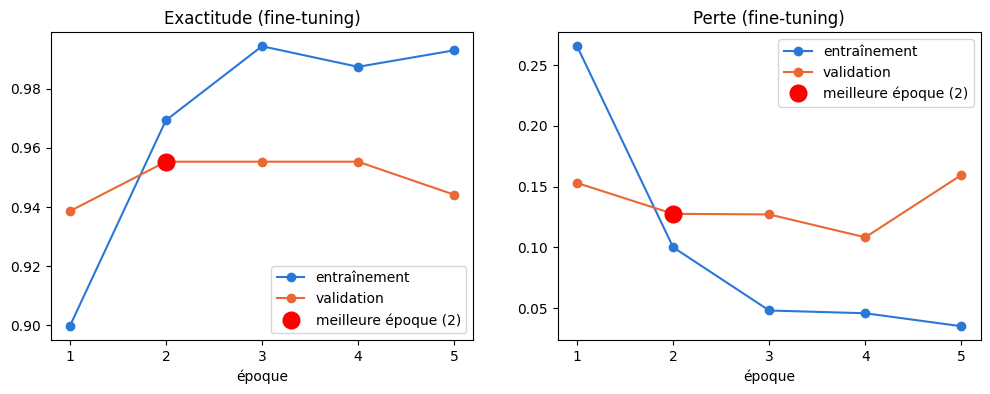

Validation : 93,9 % avant, 95,5 % après (+1,7 points), pour 1,1 minutes de plus.


In [16]:
fine_tuning(projet)

**Résultat attendu**

```text
20 dernières couches dégelées. Poids entraînés maintenant : 1 209 923
Époque  1/5 · exactitude entraînement 90,0 % · validation 93,9 % · 17 s
…
Époque  5/5 · exactitude entraînement 99,3 % · validation 94,4 % · 10 s
Validation : 93,9 % avant, 95,5 % après (+1,7 points), pour 1,1 minutes de plus.
```

Puis les deux courbes du fine-tuning.

**Questions**
- **Q11 (bonus).** Le fine-tuning a-t-il amélioré la validation ? De combien de photos ? Cela valait-il les minutes en plus ?

**Réponse.** **Q11.** La validation passe de **93,9 % à 95,5 %**, soit **+1,7 point**, c'est-à-dire **3 photos** sur 179, pour environ une minute de calcul en plus sur ce portable. Un écart de 3 photos peut venir du hasard. Et l'entraînement monte à 99 % pendant que la validation redescend à la dernière époque : le sur-apprentissage guette. Ici, le fine-tuning ne valait pas vraiment le coup : mieux vaut d'abord retirer les étiquettes fausses (la peintre rangée dans `tulipe`) et ajouter de la variété.

## Ce qu'il faut rendre

Un notebook Colab par binôme, avec les deux noms en haut. Il doit contenir :
- toutes les cellules, **exécutées** ;
- vos prédictions (« Je prédis ») et vos réponses à Q1 à Q10 ;
- vos deux décisions : les photos écartées, et les limites du modèle ;
- la fiche `fiche_modele.md`.

## Testé sur d'autres dossiers

Pour vérifier que le carnet est réutilisable, le carnet ÉLÈVE a été exécuté de bout en bout sur deux autres dossiers, fabriqués avec le script [`make_dataset_exemple.py`](../../scripts/make_dataset_exemple.py) à partir des autres fleurs du jeu source. Seule la cellule RÉGLAGES a changé (avec `EPOQUES = 2`, pour aller vite) :

| Dossier | Classes | Partage | Exactitude (2 époques) | Modèle paresseux |
|---|---|---|---|---|
| 2 classes | `marguerite`, `tournesol` | 480 / 120 | 80,0 % | 49,2 % |
| 4 classes | `marguerite`, `rose`, `tournesol`, `tulipe` | 960 / 240 | 86,2 % | 21,2 % |

Toutes les cellules tournent, bonus compris. Le nombre de classes, leurs noms, la taille de la dernière couche (2 562 poids pour 2 classes, 5 124 pour 4), la matrice de confusion et les probabilités suivent seuls. Avec 2 époques seulement, l'exactitude n'a pas fini de monter : avec 10 époques, elle progresse encore.

## Glossaire

| Mot | En une phrase |
|---|---|
| **Pixel** | Un point de la photo, décrit par 3 nombres entre 0 et 255 (rouge, vert, bleu). Les features sont des pixels. |
| **Classe, étiquette** | Ce qu'on veut prédire ; ici, le nom du dossier de la photo. |
| **Transfert d'apprentissage** | Réutiliser un réseau déjà entraîné, poids gelés, et ne remplacer que la dernière couche. |
| **Poids gelés** | Les poids qu'on n'entraîne plus. |
| **Époque** | Un passage du modèle sur toutes les photos d'entraînement. |
| **Validation** | Les photos mises de côté avant tout, pour l'examen. |
| **Augmenter** | Transformer un peu les photos d'entraînement, à la volée, sans changer leur classe. |
| **Sur-apprentissage** | Apprendre par cœur : l'entraînement progresse, la validation non. |
| **Confiance, seuil** | La plus grande des probabilités ; en dessous du seuil, la photo va « à vérifier par un humain ». |
| **Carte de chaleur** | Les zones de la photo qui ont le plus pesé dans la décision. |
| **Raccourci** | Le modèle a appris un indice du fond, du site ou du matériel, pas le sujet. |
| **GPU** | Une carte de calcul qui accélère beaucoup l'entraînement. |